

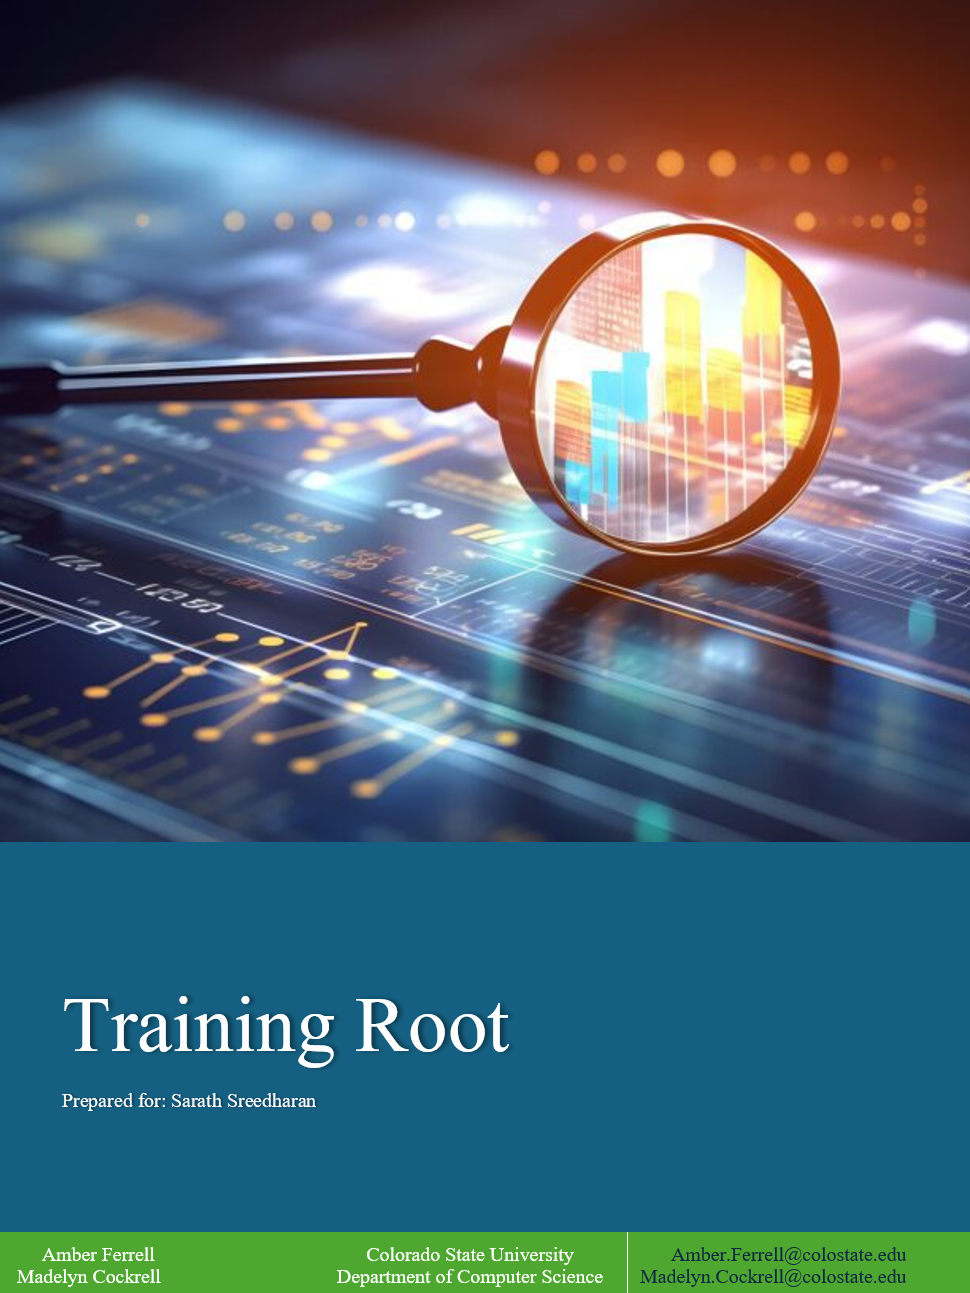

<h1 style="font-family: 'Times New Roman', Times, serif;">
    Introduction
</h1>

<div style="font-family: 'Times New Roman', Times, serif; line-height: 1.6;font-size:20px; ">
The Root project comes from the vision of creating a comprehensive parenting support app designed to foster emotional regulation and child development grounded in the Finnish education model and Montessori principles. The inspiration for the app lies in a parent first model of regulation, which posits that a caregiver’s internal emotional state is the primary catalyst for a healthy home environment. A parent cannot effectively co regulate a child while they themselves are in a state of emotional flooding or crisis especially if they did not grow up with a good parent to model from. This app starts at the root of the problem, deep in the family roots, and attempts to break toxic generational trauma by helping the parent become rooted. The name may work well as a proprietary eponym, a verb users will eventually come to use. While the full Root application will eventually integrate Finnish pedagogical concepts and the emphasis on the child’s holistic well being, the work presented here represents the essential technical foundation for such a system. By implementing a high precision classification engine to identify parental emotional states this project establishes the logic required for future  development. Utilizing a refined version of the dair ai emotion dataset, the following analysis compares a suite of classification architecturesapproaches to determine which mathematical brain most effectively captures the nuance of parental emotional shifts. We specifically use Linear Support Vector Machines and Random Forest ensembles against neural network. By establishing this baseline, we can ensure that the Root application provides accurate feedback that empowers parents to pause, reflect, and regulate before interacting with their children, effectively turning a moment of potential crisis into an opportunity for connection.</div>

<h2 style="font-family: 'Times New Roman', Times, serif;">
    Project Setup & Dependencies
<h2/>

<div style="font-family: 'Times New Roman', Times, serif; line-height: 1.6;font-size:20px; ">
Before building the Root classification engine, we establish our technical environment. The following libraries form the foundation of our analysis:


* pandas & numpy: Data manipulation and numerical operations 
* matplotlib & seaborn: Visualization suite for exploratory analysis and model evaluation 
* datasets (HuggingFace): Access to the dair-ai/emotion dataset 
* scikit-learn: Core ML pipeline including TF-IDF vectorization, SVM, Random Forest, and evaluation metrics 


We load the  dair-ai/emotion dataset, a benchmark collection of English Twitter messages annotated with six emotional categories. </br>
This dataset serves as our proxy for parental emotional expression until domain-specific data can be collected.
</div>

In [67]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import string
from datasets import load_dataset
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras import regularizers
from tensorflow.keras.layers import Input

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

dataset = load_dataset("dair-ai/emotion")
df = dataset['train'].to_pandas()

print("Label values:", df['label'].unique())
print("\nLabel distribution:")
print(df['label'].value_counts().sort_index())
print("\nDataset info:")
print(dataset['train'].features)

Label values: [0 3 2 5 4 1]

Label distribution:
label
0    4666
1    5362
2    1304
3    2159
4    1937
5     572
Name: count, dtype: int64

Dataset info:
{'text': Value('string'), 'label': ClassLabel(names=['sadness', 'joy', 'love', 'anger', 'fear', 'surprise'])}


<h2 style="font-family: 'Times New Roman', Times, serif;">
    Exploratory Data Analysis
<h2/>

<div style="font-family: 'Times New Roman', Times, serif; line-height: 1.6; font-size:20px">
Before building any classification models, we must understand the landscape of our data. The dair-ai/emotion dataset contains six emotion categories, but as we will see, these classes are  significantly imbalanced This is a critical consideration for our model selection and evaluation. In this section, we examine the numeric to text label mapping (0:sadness, 1:joy, 2:love, 3:anger, 4:fear, 5:surprise), class distribution and imbalance severity and sentence length characteristics across emotional states. Understanding these distributions will inform our preprocessing decisions and help contextualize model performance on minority classes like love and surprise.
</div>


Counts per Class:
emotion
joy         5362
sadness     4666
anger       2159
fear        1937
love        1304
surprise     572
Name: count, dtype: int64

Mean Word Count per Emotion:
emotion
love        20.700153
surprise    19.970280
joy         19.498135
anger       19.229736
fear        18.844605
sadness     18.361980
Name: word_count, dtype: float64


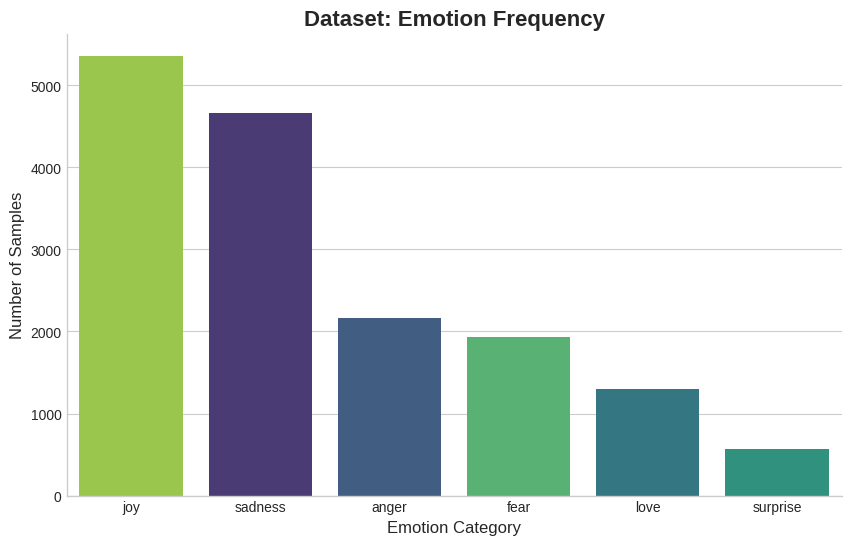

In [46]:

label_names = dataset['train'].features['label'].names
df['emotion'] = df['label'].map({i: name for i, name in enumerate(label_names)})

df['char_count'] = df['text'].str.len()
df['word_count'] = df['text'].str.split().str.len()

print("\nCounts per Class:")
print(df['emotion'].value_counts())

print("\nMean Word Count per Emotion:")
print(df.groupby('emotion')['word_count'].mean().sort_values(ascending=False))

plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='emotion', hue='emotion', legend=False, order=df['emotion'].value_counts().index, palette='viridis')

plt.title('Dataset: Emotion Frequency', fontsize=16, fontweight='bold')
plt.xlabel('Emotion Category', fontsize=12)
plt.ylabel('Number of Samples', fontsize=12)
sns.despine()
plt.show()

<h2 style="font-family: 'Times New Roman', Times, serif;">
    Class Imbalance 
<h2/>

<div style="font-family: 'Times New Roman', Times, serif; line-height: 1.6; font-size:20px; ">
With  5,362 joy samples compared to only  572 surprise samples, our dataset exhibits a nearly  10:1 imbalance between the largest and smallest classes. This imbalance has important implications. Accuracy alone is misleading. A model that predicts joy every time would achieve ~34% accuracy without learning anything meaningful 
Minority classes need protection. We must use  class_weight='balanced' and monitor  per-class F1 scores to ensure love and surprise are not ignored 
Stratified splitting is essential here. Train/test splits must preserve class proportions to avoid evaluation on unrepresentative samples.
These considerations will guide our model selection and evaluation strategy throughout the remainder of this analysis.
</div>

<h2 style="font-family: 'Times New Roman', Times, serif;">
    Sentence Length Analysis
</h2>

<div style="font-family: 'Times New Roman', Times, serif; line-height: 1.6; font-size:20px; ">
Beyond class frequency, we examine whether different emotional expressions exhibit distinct structural patterns. Specifically, we calculate character count and word count per message to determine if certain emotions tend to be expressed more verbosely. This analysis serves two purposes. If sentence length varies systematically by emotion, it may serve as a useful feature for classification. As for the neural network, understanding typical sequence lengths helps determine appropriate padding/truncation thresholds. As shown below, love and surprise messages tend to be slightly longer on average, while sadness messages are the most concise. However, the differences are modest, suggesting that semantic content will be the primary driver of classification performance.
</div>

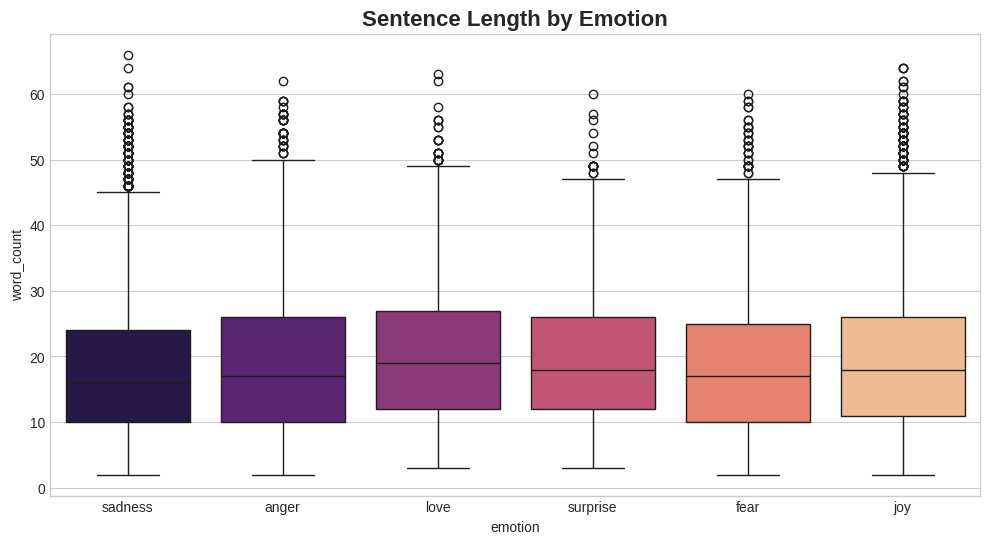

In [47]:

# Plot word count distribution by emotion
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='emotion', hue='emotion', legend=False, y='word_count', palette='magma')
plt.title('Sentence Length by Emotion', fontsize=16, fontweight='bold')
plt.show()





<h2 style="font-family: 'Times New Roman', Times, serif;">
Visualizing Semantic Space
<h2/>

<div style="font-family: 'Times New Roman', Times, serif; line-height: 1.6; font-size:20px; ">
To understand how our classification engine will interpret these texts, we project the high-dimensional TF-IDF vocabulary into a lower-dimensional space using Principal Component Analysis (PCA). The resulting visualizations show distinct emotional islands, but also significant semantic overlap, particularly between joy and love.

This visual evidence justifies our need for a model with a carefully tuned margin; a rigid classifier would likely overfit to the noisy, shared vocabulary between these emotional states, while a softer margin will allow for better generalization.</div>

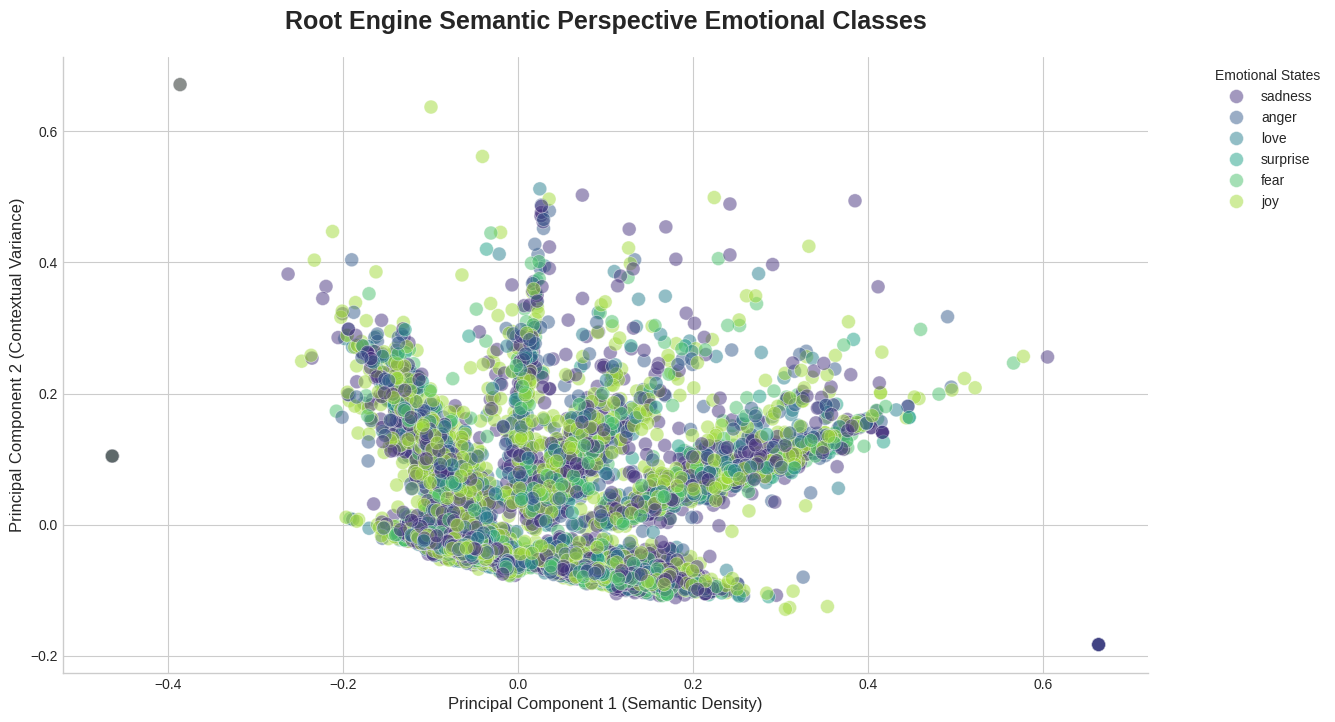

In [48]:
# Resetting the DataFrame to the original labels
# 0: sadness, 1: joy, 2: love, 3: anger, 4: fear, 5: surprise
label_names = dataset['train'].features['label'].names
df['original_label'] = df['label'].map({i: name for i, name in enumerate(label_names)})

# 1. Re-vectorize without consolidation
tfidf_1 = TfidfVectorizer(max_features=2500, stop_words='english')
X_1 = tfidf_1.fit_transform(df['text']).toarray()

# 2. PCA on the 6 original classes
pca_1 = PCA(n_components=2, random_state=42)
coords_1  = pca_1.fit_transform(X_1 )

# 3. Plotting the   Truth
plt.figure(figsize=(14, 8))
sns.scatterplot(
    x=coords_1[:, 0], 
    y=coords_1[:, 1], 
    hue=df['original_label'],
    palette='viridis',
    s=100, 
    alpha=0.5,
    edgecolor='w',
    linewidth=0.5
)

plt.title('Root Engine Semantic Perspective Emotional Classes', 
          fontsize=18, fontweight='bold', pad=20)
plt.xlabel('Principal Component 1 (Semantic Density)', fontsize=12)
plt.ylabel('Principal Component 2 (Contextual Variance)', fontsize=12)
plt.legend(title='Emotional States', bbox_to_anchor=(1.05, 1), loc='upper left')
sns.despine()
plt.show()



<div style="font-family: 'Times New Roman', Times, serif; line-height: 1.6; font-size:20px;">
As the scatter plot illustrates, projecting every individual text sample into a 2D plane creates a dense, overlapping cloud. While we can observe some general clustering, the sheer volume of noise and shared vocabulary obscures the distinct boundaries of our classes. To cut through this density and locate the true north of each emotional state, we must strip away the outliers. By calculating the centroid, the geometric center of mass for each category, we can distill thousands of overlapping messages down to their core semantic identities.
</div>

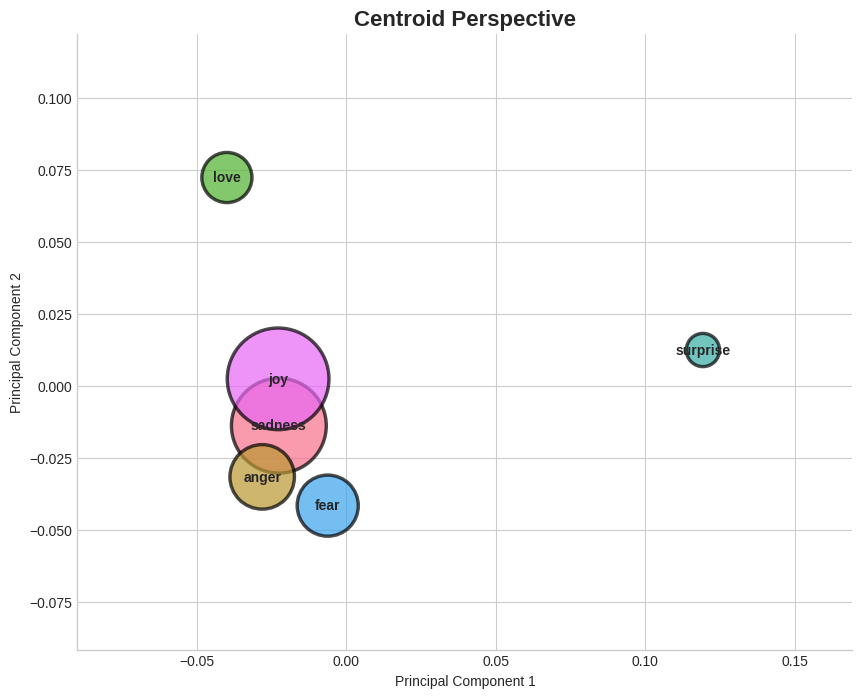

In [49]:
#  Calculate Centroids for the original 6 categories
unique_emotions = df['emotion'].unique()
centroids = np.array([X_1[df['emotion'] == e].mean(axis=0) for e in unique_emotions])

# PCA on  these 6 centroids
pca_centroids = PCA(n_components=2)
centroid_coords = pca_centroids.fit_transform(centroids)

# Plotting the 6
plt.figure(figsize=(10, 8))

# Get counts for bubble sizing
counts = df['emotion'].value_counts()
bubble_sizes = [counts[e] for e in unique_emotions]

sns.scatterplot(
    x=centroid_coords[:, 0], 
    y=centroid_coords[:, 1], 
    hue=unique_emotions,
    palette='husl',
    s=bubble_sizes, 
    alpha=0.7,
    edgecolor='black',
    legend=False
)

# Label the bubbles
for i, emotion in enumerate(unique_emotions):
    plt.text(centroid_coords[i, 0], centroid_coords[i, 1], emotion, 
             fontsize=10, fontweight='bold', ha='center', va='center')

plt.title('Centroid Perspective', fontsize=16, fontweight='bold')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

# Zooming in to see the relationships
padding = 0.05
plt.xlim(centroid_coords[:, 0].min() - padding, centroid_coords[:, 0].max() + padding)
plt.ylim(centroid_coords[:, 1].min() - padding, centroid_coords[:, 1].max() + padding)

sns.despine()
plt.show()

<h2 style="font-family: 'Times New Roman', Times, serif; line-height: 1.6;">
Adding Dimensionality
<h2/>
<div style="font-family: 'Times New Roman', Times, serif; line-height: 1.6; font-size:20px;">
While the 2D visualization provides a foundational understanding of our semantic landscape, the dense overlap between certain emotional states makes it difficult to clearly delineate the boundaries. Text data is inherently high-dimensional, and squashing it into just two principal components forces visual compromises.

By introducing a third component, we can look at the data from another angle. This added depth helps us visualize the true separation of these emotional islands, revealing nuances in the variance that a flat plane obscures.</div>

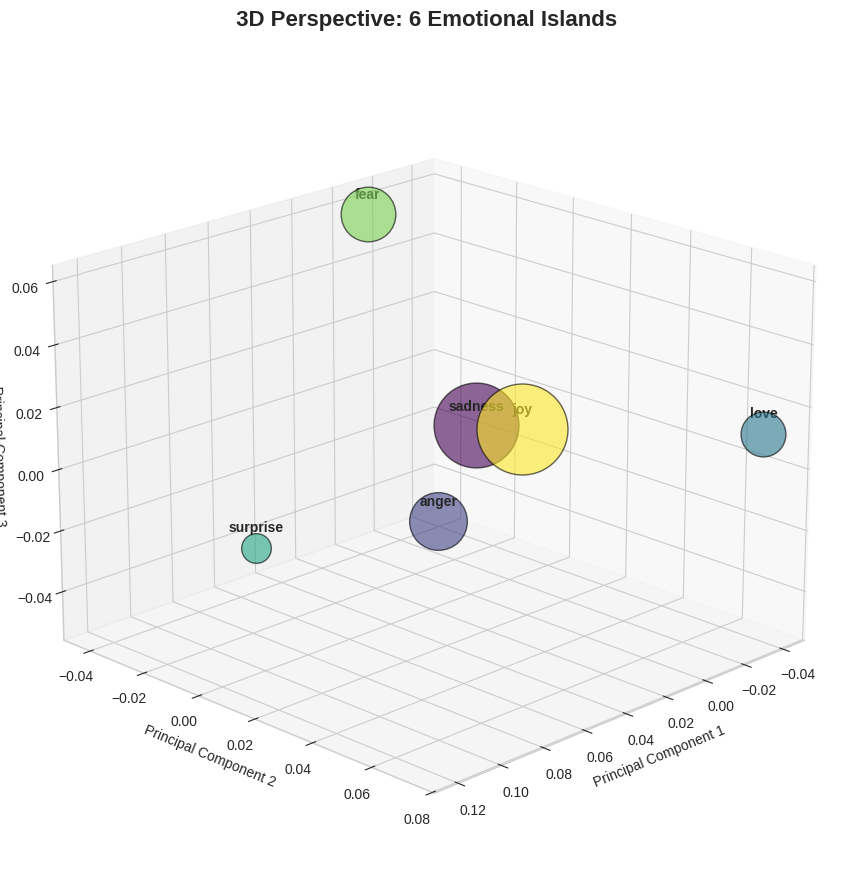

Total Explained Variance (3 Components): 82.27%


In [50]:
from mpl_toolkits.mplot3d import Axes3D

# Calculate Centroids for the original 6 categories
unique_emotions = df['emotion'].unique()
# Using the X_1 (TF-IDF) we generated in the previous step
centroids = np.array([X_1[df['emotion'] == e].mean(axis=0) for e in unique_emotions])

# PCA with 3 components to add the Z-axis
pca_3d = PCA(n_components=3)
centroid_coords_3d = pca_3d.fit_transform(centroids)

# Setup the 3D Plot
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection='3d')

# Scaling and Colors
counts = df['emotion'].value_counts()
bubble_sizes_3d = [counts[e] * 0.8 for e in unique_emotions]
colors = plt.cm.viridis(np.linspace(0, 1, len(unique_emotions)))

# Plotting the 6 Islands
for i, emotion in enumerate(unique_emotions):
    ax.scatter(
        centroid_coords_3d[i, 0], 
        centroid_coords_3d[i, 1], 
        centroid_coords_3d[i, 2],
        s=bubble_sizes_3d[i],
        color=colors[i],
        alpha=0.6,
        edgecolor='black'
    )
    
    # Text labels
    ax.text(
        centroid_coords_3d[i, 0], 
        centroid_coords_3d[i, 1], 
        centroid_coords_3d[i, 2] + 0.005,
        emotion, 
        fontsize=10, 
        fontweight='bold',
        ha='center'
    )

# THE STEERING CONTROLS
# elev: height of the camera (0 is side-view, 90 is top-down)
# azim: rotation around the islands (0 to 360)
ax.view_init(elev=20, azim=45)

ax.set_title(' 3D Perspective: 6 Emotional Islands', fontsize=16, fontweight='bold', pad=20)
ax.set_xlabel('Principal Component 1')
ax.set_ylabel('Principal Component 2')
ax.set_zlabel('Principal Component 3')

plt.tight_layout()
plt.show()

print(f"Total Explained Variance (3 Components): {np.sum(pca_3d.explained_variance_ratio_):.2%}")

<h2 style="font-family: 'Times New Roman', Times, serif;">
    Isolating the margin for Joy and Sadness
</h2>

<div style="font-family: 'Times New Roman', Times, serif; line-height: 1.6; font-size:20px;">
This visualization gave us a better picture than the 2D, but we still see the overlap here with sadness and joy. In such a noisy vector space, it is difficult to determine exactly where one emotion ends and the other begins. To get a closer, mathematical look at this specific boundary, we must isolate these two opposing states. By stripping away the noise of the other four classes and projecting only the centroids of joy and sadness back into our 3D space, we can explicitly measure the semantic distance between their centers of gravity. Visualizing this physical margin helps us understand the precise gap our classification engine must learn to navigate.
</div>

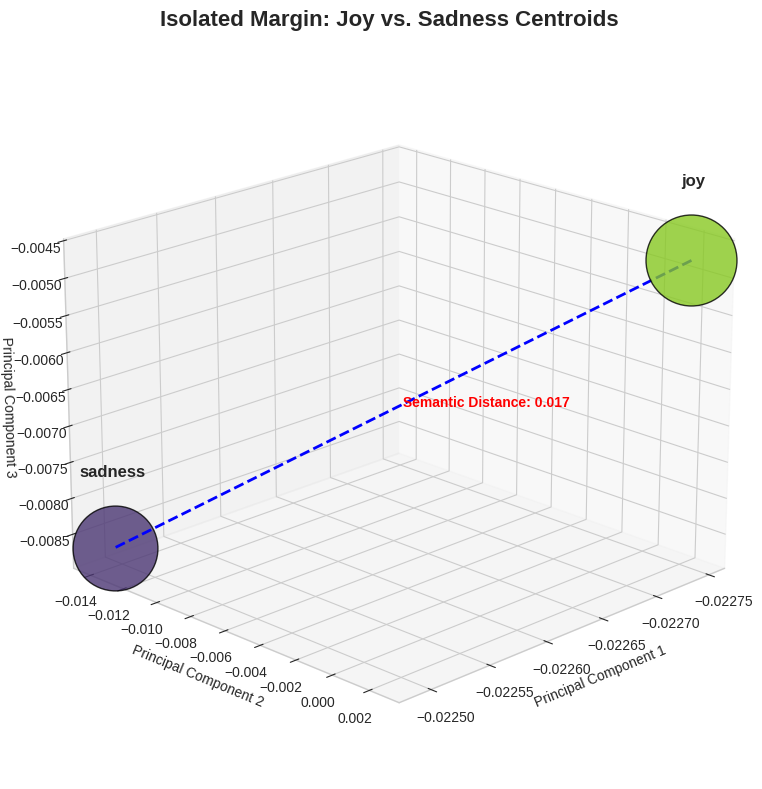

In [51]:

target_emotions = ['joy', 'sadness']
binary_centroids = np.array([X_1[df['emotion'] == e].mean(axis=0) for e in target_emotions])
binary_coords_3d = pca_3d.transform(binary_centroids)
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
counts = df['emotion'].value_counts()
sizes = [counts[e] * 0.8 for e in target_emotions]
binary_colors = ['#88C922', '#4B3673'] # High contrast for joy/sadness
for i, emotion in enumerate(target_emotions):
    ax.scatter(
        binary_coords_3d[i, 0], 
        binary_coords_3d[i, 1], 
        binary_coords_3d[i, 2],
        s=sizes[i],
        color=binary_colors[i],
        alpha=0.8,
        edgecolor='black'
    )
    
    ax.text(
        binary_coords_3d[i, 0], 
        binary_coords_3d[i, 1], 
        binary_coords_3d[i, 2] + 0.001,
        emotion, 
        fontsize=12, 
        fontweight='bold',
        ha='center'
    )

ax.plot(
    [binary_coords_3d[0, 0], binary_coords_3d[1, 0]],
    [binary_coords_3d[0, 1], binary_coords_3d[1, 1]],
    [binary_coords_3d[0, 2], binary_coords_3d[1, 2]],
    color='blue', linestyle='--', linewidth=2
)

# 6. Calculate and display the actual mathematical distance between them
distance = np.linalg.norm(binary_coords_3d[0] - binary_coords_3d[1])
ax.text(
    (binary_coords_3d[0, 0] + binary_coords_3d[1, 0]) / 2,
    (binary_coords_3d[0, 1] + binary_coords_3d[1, 1]) / 2,
    (binary_coords_3d[0, 2] + binary_coords_3d[1, 2]) / 2,
    f' Semantic Distance: {distance:.3f}', 
    color='red', fontweight='bold'
)

ax.view_init(elev=20, azim=45)
ax.set_title('Isolated Margin: Joy vs. Sadness Centroids', fontsize=16, fontweight='bold', pad=20)
ax.set_xlabel('Principal Component 1')
ax.set_ylabel('Principal Component 2')
ax.set_zlabel('Principal Component 3')
plt.tight_layout()
plt.show()

<h2 style="font-family: 'Times New Roman', Times, serif;">
Classification
</h2>

<div style="font-family: 'Times New Roman', Times, serif; line-height: 1.6; font-size:20px;">
The measurable margin between isolated centroids reveals a critical insight for our modeling strategy. While these emotional states have distinct centers of gravity, their borders are blurred by a shared, highly intense vocabulary. This visual evidence directly justifies our need for a model with a carefully tuned margin. A rigid classifier would likely overfit to the noisy, shared language between states like joy and sadness, while a softer margin will allow for better generalization. With this spatial understanding established, we now proceed to build our baseline classification engine.
</div>

In [52]:
#  Split the data
# We use stratify to ensure the tiny surprise class is represented in both sets
X_train, X_test, y_train, y_test = train_test_split(
    df['text'], 
    df['emotion'], 
    test_size=0.2, 
    random_state=42, 
    stratify=df['emotion']
)

#  Build the pipeline
max_features=5000
class_weight='balanced'
baseline_pipe = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000, stop_words='english')),
    ('svm', LinearSVC(class_weight='balanced', random_state=42))
])

#  Train the baseline
baseline_pipe.fit(X_train, y_train)

# predict and evaluate
y_pred = baseline_pipe.fit(X_train, y_train).predict(X_test)

print("Baseline Engine Performance (6-Class):\n")
print(classification_report(y_test, y_pred))



Baseline Engine Performance (6-Class):

              precision    recall  f1-score   support

       anger       0.86      0.87      0.86       432
        fear       0.85      0.88      0.87       387
         joy       0.90      0.88      0.89      1072
        love       0.74      0.85      0.79       261
     sadness       0.94      0.89      0.91       933
    surprise       0.75      0.82      0.78       115

    accuracy                           0.88      3200
   macro avg       0.84      0.87      0.85      3200
weighted avg       0.88      0.88      0.88      3200



<div style="font-family: 'Times New Roman', Times, serif; line-height: 1.6; font-size:20px;">
Our baseline engine achieves a strong overall accuracy of 88%, proving that a linear SVM is a highly capable architecture for this task. It performs exceptionally well on the largest classes, such as sadness and joy. However, looking at the F1 scores for our minority classes, specifically love and surprise, reveals structural weaknesses. The text report tells us the engine is making mistakes, but it doesn't tell us where. To determine if the model is confusing semantically similar emotions, such as misclassifying love as joy, we map the exact predictions using a confusion matrix.
</div>

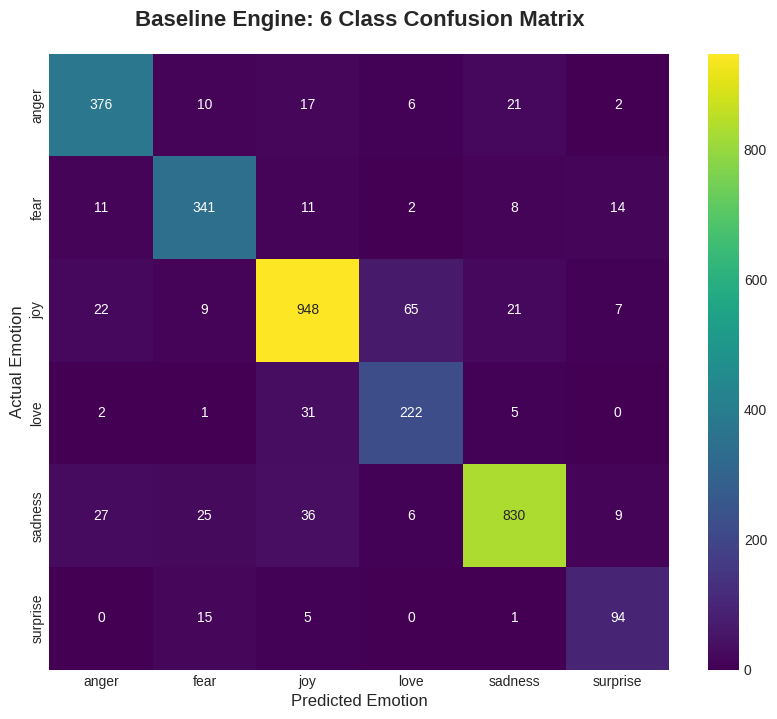

In [53]:
#Generate the Confusion Matrix
cm = confusion_matrix(y_test, y_pred, labels=baseline_pipe.classes_)

# Plotting for the report
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='viridis',
    xticklabels=baseline_pipe.classes_, 
    yticklabels=baseline_pipe.classes_
)

plt.title('Baseline Engine: 6 Class Confusion Matrix', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Predicted Emotion', fontsize=12)
plt.ylabel('Actual Emotion', fontsize=12)
plt.show()

<div style="font-family: 'Times New Roman', Times, serif; line-height: 1.6; font-size:20px;">
The confusion matrix provides a granular view of our baseline engine's decision-making, and it immediately validates the structural challenges we identified during our exploratory data analysis. While the strong diagonal line confirms the model's overall accuracy, the off diagonal errors are highly revealing. The matrix confirms the exact noisy margin we isolated in our 3D spatial analysis; actual sadness was misclassified as joy 36 times and actual joy was misclassified as sadness 21 times. Interestingly, the matrix also reveals an even larger structural weakness within positive regulatory states, with actual joy misclassified as love 65 times, and love as joy 31 times. These specific points of failure confirm that while our baseline is strong, it requires hyperparameter tuning. Specifically, we need a softer margin to better generalize across these blurred emotional boundaries.
</div>

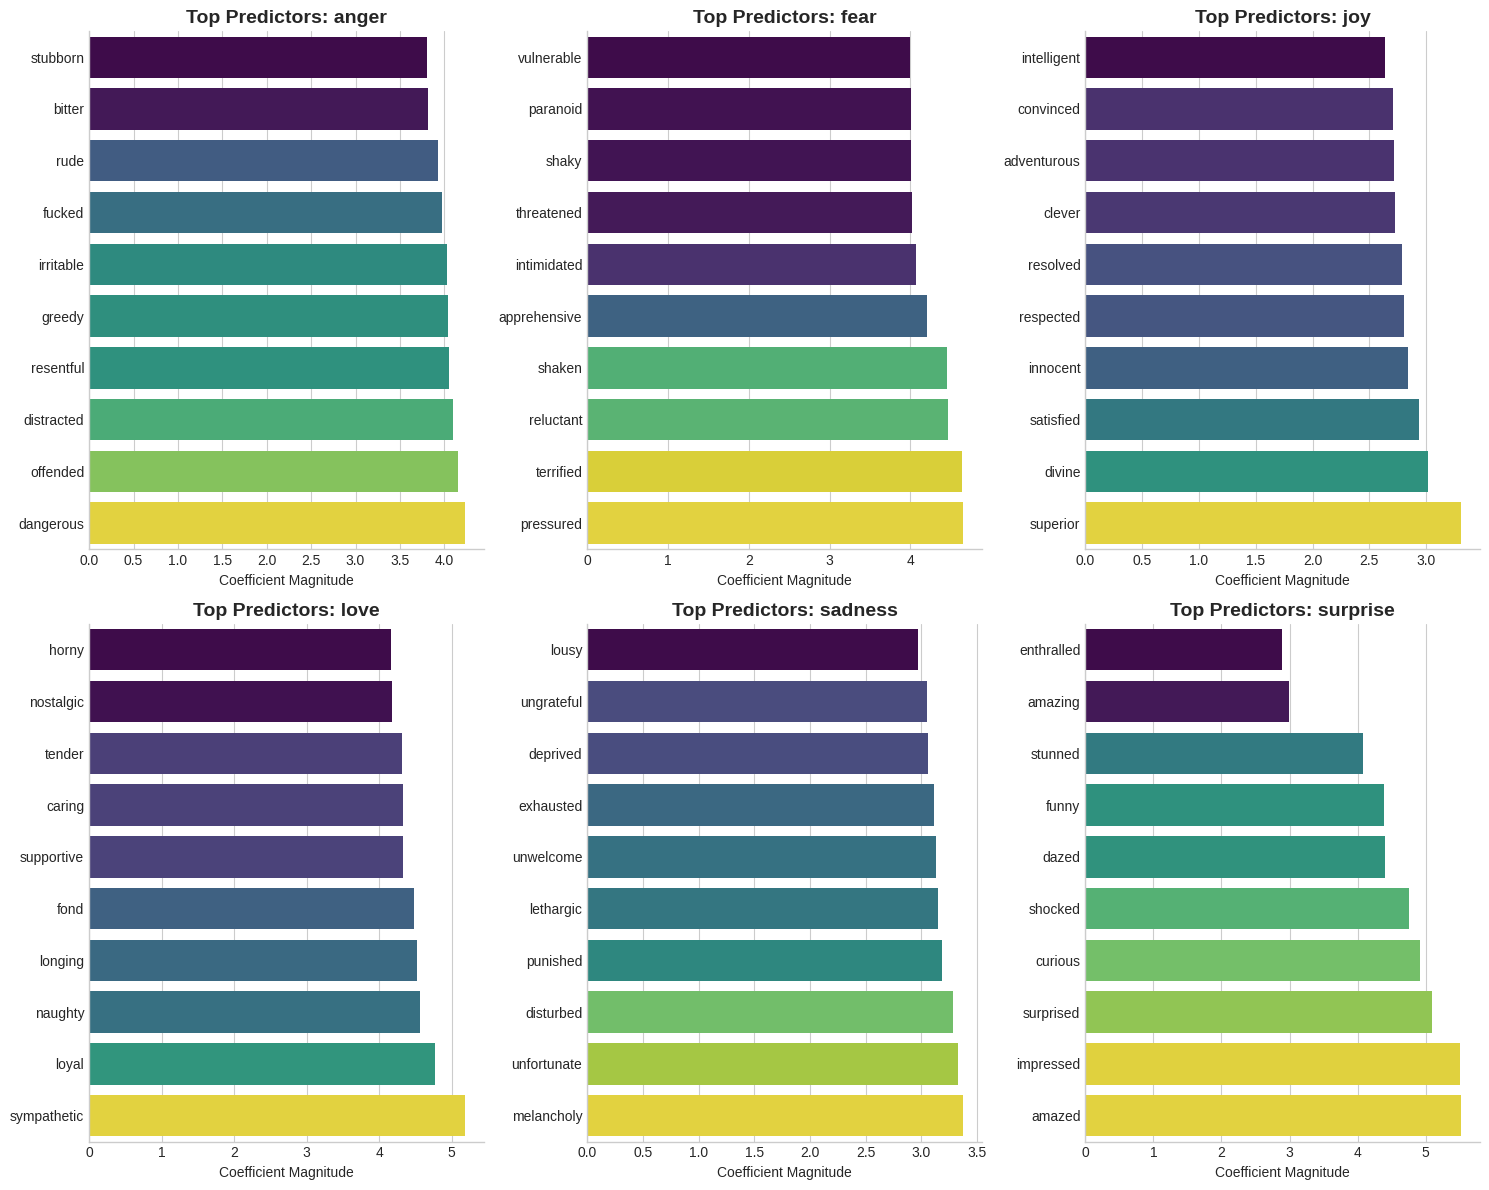

In [54]:
# Extract the coefficients from the Baseline Pipeline
# LinearSVC coefficients tell us the weight of every word in the TF-IDF vocabulary
clf = baseline_pipe.named_steps['svm']
vec = baseline_pipe.named_steps['tfidf']
feature_names = vec.get_feature_names_out()
classes = clf.classes_

#Extract top 10 words per class
plt.figure(figsize=(15, 12))

for i, class_label in enumerate(classes):
    # Sort coefficients to find the strongest positive indicators for this class
    top10_indices = np.argsort(clf.coef_[i])[-10:]
    top10_words = [feature_names[j] for j in top10_indices]
    top10_weights = [clf.coef_[i][j] for j in top10_indices]
    
    # Plotting for the report
    plt.subplot(2, 3, i+1)
    sns.barplot(x=top10_weights, y=top10_words, palette='viridis',hue=top10_weights, legend=False)
    plt.title(f'Top Predictors: {class_label}', fontsize=14, fontweight='bold')
    plt.xlabel('Coefficient Magnitude')
    sns.despine()

plt.tight_layout()
plt.show()

<div style="font-family: 'Times New Roman', Times, serif; line-height: 1.6; font-size:20px;">
These lexical footprints reveal a crucial insight about our dataset. While predictors like "melancholy" (sadness) and "terrified" (fear) align perfectly with psychological expectations, the predictors for 'love' highlight the nature of our data source. With words like "naughty" and "horny" acting as strong signals, it is clear the engine is learning the internet's conversational definition of these emotions. This starkly contrasts with the regulated, parent-child dynamic the Root app is designed to monitor. This transparency proves that while our mathematical architecture is functioning correctly, deploying the final Root application will eventually require fine-tuning on domain-specific, parental data to bridge this semantic gap.
</div>

<h2 style="font-family: 'Times New Roman', Times, serif;">
    Baseline Evaluation & Stability
</h2>

<div style="font-family: 'Times New Roman', Times, serif; line-height: 1.6; font-size:20px;">
The baseline Linear SVC engine demonstrates strong initial performance in identifying sadness and joy. However, examining the classification report and confusion matrix there are structural weaknesses in distinguishing minority classes like surprise. Before adjusting the mathematical architecture, we must verify that this performance is not an artifact of our specific train/test split. By applying 5 fold cross validation, we test the engine's stability across different subsets of the data, ensuring that our baseline metrics are reliable before we attempt hyperparameter optimization.
</div>

In [55]:
# Setup the Pipeline again for the Cross-Val
cv_pipe = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000, stop_words='english')),
    ('svm', LinearSVC(class_weight='balanced', random_state=42))
])

#run 5fold cross validation
cv_scores = cross_val_score(cv_pipe, df['text'], df['emotion'], cv=5)

print(f"Individual CV Scores: {cv_scores}")
print(f"Mean Accuracy: {cv_scores.mean():.4f}")
print(f"Standard Deviation: {cv_scores.std():.4f}")

Individual CV Scores: [0.894375  0.89      0.875     0.8746875 0.8946875]
Mean Accuracy: 0.8858
Standard Deviation: 0.0091


<h2 style="font-family: 'Times New Roman', Times, serif;">
    Hyperparameter Optimization: Tuning the Decision Boundary
</h2>

<div style="font-family: 'Times New Roman', Times, serif; line-height: 1.6; font-size:20px;">
The cross-validation scores validate the structural integrity of our model. With a mean accuracy of 88.58% and a near-zero standard deviation, we can definitively say our baseline performance is highly stable and not an artifact of a lucky train/test split. Now that we trust the mathematical foundation of our baseline, we can safely fine-tune its mechanics. 

As established by our confusion matrix and PCA visual analysis, the linear SVM's rigid margin struggles to separate semantically overlapping states like joy, love, and sadness. To correct this, we will optimize the 'C' parameter of our Linear SVC. This parameter dictates the penalty for misclassified data points. A high 'C' value forces a hard, rigid margin that strictly categorizes every point, which risks overfitting to the noisy internet vocabulary we just identified. By testing a range of 'C' magnitudes, we intend to find a softer optimal margin that allows the engine to generalize more effectively across those blurred emotional boundaries.
</div>

In [56]:
# Testing 3 different strengths of C to see which yields the best F1-score
for c_value in [0.1, 1.0, 10]:
    tune_pipe = Pipeline([
        ('tfidf', TfidfVectorizer(max_features=5000, stop_words='english')),
        ('svm', LinearSVC(C=c_value, class_weight='balanced', random_state=42, max_iter=2000))
    ])
    
    tune_pipe.fit(X_train, y_train)
    y_tune_pred = tune_pipe.predict(X_test)
    
    print(f"--- Results for C={c_value} ---")
    print(f"Overall Accuracy: {accuracy_score(y_test, y_tune_pred):.4f}")
    # Specifically checking the F1 for 'love' to see if it improves
    report = classification_report(y_test, y_tune_pred, output_dict=True)
    print(f"Love F1-Score: {report['love']['f1-score']:.4f}\n")

--- Results for C=0.1 ---
Overall Accuracy: 0.8809
Love F1-Score: 0.7973

--- Results for C=1.0 ---
Overall Accuracy: 0.8784
Love F1-Score: 0.7900

--- Results for C=10 ---
Overall Accuracy: 0.8562
Love F1-Score: 0.7495



<h2 style="font-family: 'Times New Roman', Times, serif; line-height: 1.6;">
Results
</h2>

<div style="font-family: 'Times New Roman', Times, serif; line-height: 1.6; font-size:20px;">
The results clearly indicate that C = 0.1 is the optimal parameter. The fact that a lower C value improved the F1 score for love, from 0.7900 to 0.7973, while maintaining the highest overall accuracy 88.09% proves that the semantic overlap between states like joy and love is handled best with a soft margin. By penalizing the model less for individual noisy data points, it generalizes better and avoids overfitting to the shared vocabulary. We have officially optimized our baseline engine: a Linear SVM operating with a soft margin of C=0.1, functionally verified by cross-validation.
</div>

<h2 style="font-family: 'Times New Roman', Times, serif;">
    Aligning with the Root Architecture
</h2>

<div style="font-family: 'Times New Roman', Times, serif; line-height: 1.6; font-size:20px;">
While classifying six distinct emotions is standard for the dair-ai dataset, the Root application requires functional feedback tailored to a parent's regulatory state. A parent experiencing joy or love operates from the same regulated baseline, whereas anger and fear demand different de-escalation protocols. To align our mathematical model with the app's pedagogical goals, we consolidate the original six emotions into five functional states. This mapping simplifies the decision boundary for our algorithms and ensures the engine outputs actionable data for the user interface. We re-evaluate our optimized SVM against this new operational standard, followed by a Random Forest ensemble to determine if non-linear decision trees can better capture the boundaries of these newly defined states.
</div>

In [57]:

# Mapping emotions to functional states for the app
mapping = {
    'joy': 'calm/in-control',
    'love': 'calm/in-control',
    'sadness': 'sadness/disappointment',
    'anger': 'anger/frustration',
    'fear': 'fear/anxiety',
    'surprise': 'confusion/uncertainty'
}

df['root_emotion'] = df['emotion'].map(mapping)

#  Re-split with the new labels
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    df['text'], 
    df['root_emotion'], 
    test_size=0.2, 
    random_state=42, 
    stratify=df['root_emotion']
)


In [58]:
#build on optimized pipeline using the C=0.1 
svm_consolidated_pipe = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000, stop_words='english')),
    ('svm', LinearSVC(C=0.1, class_weight='balanced', random_state=42))
])

#  Train on the mapped labels (y_train_c)
svm_consolidated_pipe.fit(X_train_c, y_train_c)

# Predict and Evaluate
y_svm_c_pred = svm_consolidated_pipe.predict(X_test_c)

print("SVM Performance (Consolidated Mapping):\n")
print(classification_report(y_test_c, y_svm_c_pred))


SVM Performance (Consolidated Mapping):

                        precision    recall  f1-score   support

     anger/frustration       0.86      0.88      0.87       432
       calm/in-control       0.94      0.95      0.95      1333
 confusion/uncertainty       0.63      0.94      0.75       115
          fear/anxiety       0.90      0.79      0.84       387
sadness/disappointment       0.94      0.90      0.92       933

              accuracy                           0.91      3200
             macro avg       0.85      0.89      0.86      3200
          weighted avg       0.91      0.91      0.91      3200




<h2 style="font-family: 'Times New Roman', Times, serif; line-height: 1.6;">
SVM Performance
</h2>
<div style="font-family: 'Times New Roman', Times, serif; line-height: 1.6; font-size:20px;">
The consolidation of our emotional categories yields an immediate and significant performance boost, pushing our overall accuracy to 91%. More importantly, examining the precision and recall scores showed that our structural realignment directly solved the mathematical bottleneck identified earlier. By mapping both joy and love into a single calm/in-control state, the model no longer incurs a penalty for confusing their overlapping vocabulary. The engine achieves an outstanding 0.95 F1-score for this baseline regulatory state. While confusion/uncertainty still struggles with precision (0.63), its high recall (0.94) ensures the app rarely misses a parent in a confused state, prioritizing safety over exactness. Having established a highly capable linear baseline, our next step is to test if non-linear architectures can capture these boundaries even more effectively.
</div>

In [59]:
# Build and Train the Random Forest
# n_estimators=100: We are building 100 different decision trees
rf_pipe = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000, stop_words='english')),
    ('rf', RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42))
])

rf_pipe.fit(X_train_c, y_train_c)
y_rf_pred = rf_pipe.predict(X_test_c)

print("Random Forest Performance (Consolidated):\n")
print(classification_report(y_test_c, y_rf_pred))

Random Forest Performance (Consolidated):

                        precision    recall  f1-score   support

     anger/frustration       0.85      0.84      0.84       432
       calm/in-control       0.92      0.94      0.93      1333
 confusion/uncertainty       0.68      0.77      0.72       115
          fear/anxiety       0.86      0.83      0.85       387
sadness/disappointment       0.93      0.90      0.91       933

              accuracy                           0.90      3200
             macro avg       0.85      0.86      0.85      3200
          weighted avg       0.90      0.90      0.90      3200



<h2 style="font-family: 'Times New Roman', Times, serif;">
    Visualizing the Architectural Showdown
</h2>

<div style="font-family: 'Times New Roman', Times, serif; line-height: 1.6; font-size:20px;">
To fully grasp how the linear hyperplane outperformed the ensemble of decision trees, we map their F1-scores side-by-side across all five functional states. This comparative visualization highlights exactly where the Random Forest loses ground  in our crucial calm/in-control state. Seeing this performance gap solidifies our decision to carry the Linear SVM forward as our primary traditional ML baseline.
</div>

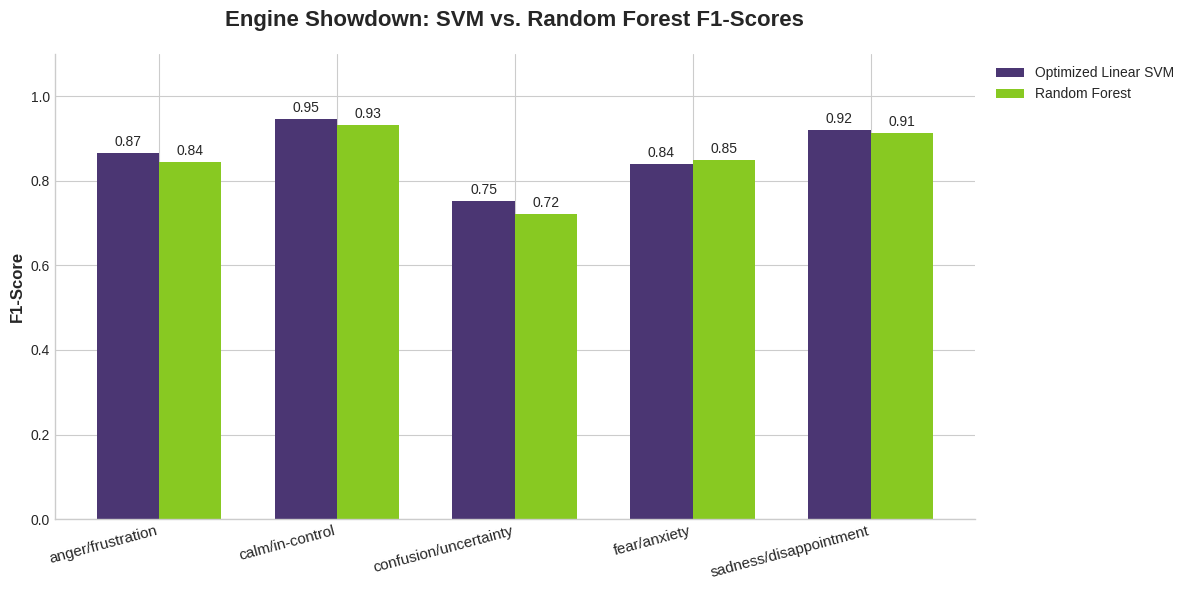

In [60]:
# extract the classification reports as dictionaries
svm_report = classification_report(y_test_c, y_svm_c_pred, output_dict=True)
rf_report = classification_report(y_test_c, y_rf_pred, output_dict=True)

# get the unique classes (ignoring 'accuracy', 'macro avg', 'weighted avg')
classes = [c for c in svm_report.keys() if c not in ['accuracy', 'macro avg', 'weighted avg']]

#extract the F1-scores for each class
svm_f1 = [svm_report[c]['f1-score'] for c in classes]
rf_f1 = [rf_report[c]['f1-score'] for c in classes]

# Set up the grouped bar chart
x = np.arange(len(classes))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 6))
rects1 = ax.bar(x - width/2, svm_f1, width, label='Optimized Linear SVM', color='#4B3673')
rects2 = ax.bar(x + width/2, rf_f1, width, label='Random Forest', color='#88C922')

# addd labels, title, and formatting
ax.set_ylabel('F1-Score', fontsize=12, fontweight='bold')
ax.set_title('Engine Showdown: SVM vs. Random Forest F1-Scores', fontsize=16, fontweight='bold', pad=20)
ax.set_xticks(x)
ax.set_xticklabels(classes, rotation=15, ha='right', fontsize=11)
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left')

#add the exact numbers on top of the bars
ax.bar_label(rects1, padding=3, fmt='%.2f')
ax.bar_label(rects2, padding=3, fmt='%.2f')

sns.despine()
plt.tight_layout()
plt.ylim(0, 1.1)
plt.show()

<div style="font-family: 'Times New Roman', Times, serif; line-height: 1.6; font-size:20px;">
The results from our Random Forest ensemble provide a crucial architectural insight. With an overall accuracy of 90%, the non-linear decision trees slightly underperformed our optimized Linear SVM 91%. The F1-score for our critical calm/in-control state dropped from 0.95 to 0.93. This tells us that in the high-dimensional, sparse vector space created by TF-IDF, a well-tuned linear hyperplane actually separates these emotional boundaries more effectively than complex ensemble trees. Having maximized the potential of word frequency algorithms, we have reached the limits of what we can achieve by looking at vocabulary in isolation. If we want to improve the engine's understanding of parental regulation further, we must start processing the sequential context of the sentences. To accomplish this, we transition to our final architecture, a neural network.
</div>

<h2 style="font-family: 'Times New Roman', Times, serif;">
    Deep Learning Architecture: Neural Network
</h2>

<div style="font-family: 'Times New Roman', Times, serif; line-height: 1.6; font-size:20px;">
While TF-IDF approaches excel at identifying keyword frequency, they inherently strip away the sequential context of a sentence. A parent's emotional expression is often nuanced, relying on word order and phrasing rather than isolated vocabulary. To address this, we construct a deep learning architecture using TensorFlow/Keras. By replacing sparse TF-IDF vectors with a dense Embedding layer, this neural network maps words into a continuous vector space where semantic similarities are learned geometrically. A Global Average Pooling layer condenses this spatial data, passing it through a dense, non-linear hidden layer to output the final functional state probability.
</div>

In [68]:

# Encode labels using one-hot encoding
le = LabelEncoder()
y_train_int = le.fit_transform(y_train_c)
y_test_int = le.transform(y_test_c)

y_train_one_hot = tf.keras.utils.to_categorical(y_train_int, num_classes=5)
y_test_one_hot = tf.keras.utils.to_categorical(y_test_int, num_classes=5)

# Prepare the TF-IDF Data
vec_nn = TfidfVectorizer(max_features=5000, stop_words='english')
X_train_nn = vec_nn.fit_transform(X_train_c).toarray()
X_test_nn = vec_nn.transform(X_test_c).toarray()

# Build the L2 Regularized MLP
reg = regularizers.l2(1e-4)

nn_model = Sequential()
# Define the input shape as its own object
nn_model.add(Input(shape=(5000,)))
# Now the first Dense layer doesn't need to hold the input_shape
nn_model.add(Dense(64, activation='relu', 
                   kernel_regularizer=reg, bias_regularizer=reg))
nn_model.add(Dense(32, activation='relu', 
                   kernel_regularizer=reg, bias_regularizer=reg))
nn_model.add(Dense(5, activation='softmax'))

# Compile the model
opt = tf.keras.optimizers.Adam()
loss_fn = tf.keras.losses.CategoricalCrossentropy()
nn_model.compile(loss=loss_fn, optimizer=opt, metrics=['accuracy'])
print("Training Multi-Layer Perceptron...\n")

# Train the network
history = nn_model.fit(
    X_train_nn, y_train_one_hot,
    batch_size=32, 
    epochs=15, 
    verbose=1, 
    validation_data=(X_test_nn, y_test_one_hot)
)

# Evaluate Predictions
y_nn_prob = nn_model.predict(X_test_nn)
y_nn_pred = np.argmax(y_nn_prob, axis=1)

print("\nMLP Performance Consolidated:\n")
print(classification_report(y_test_int, y_nn_pred, target_names=le.classes_))

Training Multi-Layer Perceptron...

Epoch 1/15


400/400 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.6355 - loss: 0.9654 - val_accuracy: 0.8556 - val_loss: 0.4874
Epoch 2/15
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9204 - loss: 0.3009 - val_accuracy: 0.8928 - val_loss: 0.3487
Epoch 3/15
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9723 - loss: 0.1609 - val_accuracy: 0.8975 - val_loss: 0.3493
Epoch 4/15
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9840 - loss: 0.1187 - val_accuracy: 0.9000 - val_loss: 0.3544
Epoch 5/15
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9885 - loss: 0.1020 - val_accuracy: 0.8997 - val_loss: 0.3751
Epoch 6/15
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9904 - loss: 0.0932 - val_accuracy: 0.8922 - val_loss: 0.3917
Epoch 7/15
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9910 - loss: 0.0907 - val_accuracy: 0.8972 - val_loss: 0.4098
Epoch 8/15
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9928 - loss: 0.0868 - val_accuracy: 0.8925 - val_

<h2 style="font-family: 'Times New Roman', Times, serif; line-height: 1.6;">
Results
</h2>
<div style="font-family: 'Times New Roman', Times, serif; line-height: 1.6; font-size:20px;">
The classification report for our Multi-Layer Perceptron created an overall accuracy of 89%, which falls slightly short of both our Random Forest 90% and our optimized Linear SVM 91%. While the network performs well on our baseline state, calm/in-control F1: 0.93, it struggles with precision in minority classes like confusion/uncertainty. To understand exactly why this deep learning architecture failed to outperform our simpler linear baseline, we need to visualize the network's training history.
</div>

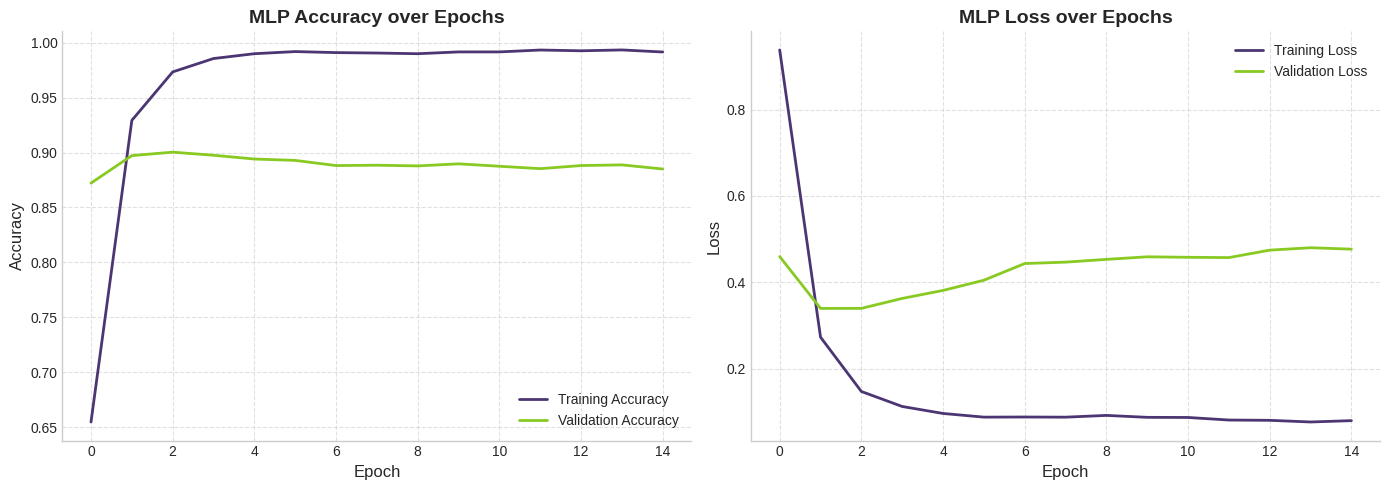

In [62]:


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot Accuracy
ax1.plot(history.history['accuracy'], label='Training Accuracy', color='#4B3673', linewidth=2)
ax1.plot(history.history['val_accuracy'], label='Validation Accuracy', color='#88C922', linewidth=2)
ax1.set_title('MLP Accuracy over Epochs', fontsize=14, fontweight='bold')
ax1.set_xlabel('Epoch', fontsize=12)
ax1.set_ylabel('Accuracy', fontsize=12)
ax1.legend(loc='lower right')
ax1.grid(True, linestyle='--', alpha=0.6)

# Plot Loss
ax2.plot(history.history['loss'], label='Training Loss', color='#4B3673', linewidth=2)
ax2.plot(history.history['val_loss'], label='Validation Loss', color='#88C922', linewidth=2)
ax2.set_title('MLP Loss over Epochs', fontsize=14, fontweight='bold')
ax2.set_xlabel('Epoch', fontsize=12)
ax2.set_ylabel('Loss', fontsize=12)
ax2.legend(loc='upper right')
ax2.grid(True, linestyle='--', alpha=0.6)

sns.despine()
plt.tight_layout()
plt.show()

<h2 style="font-family: 'Times New Roman', Times, serif; line-height: 1.6;">
Results
</h2>

<div style="font-family: 'Times New Roman', Times, serif; line-height: 1.6; font-size:20px;">
The generated learning curves visually confirm the limitations of applying a dense neural network to our specific dataset. In the Accuracy plot, we see the training metric (purple) climb steadily toward 99%, while the validation metric (green) plateaus almost immediately. This divergence is even more pronounced in the Loss plot, where the validation loss begins to curve upward after Epoch 5, displaying the classic U-shape indicative of overfitting. Even with the introduction of L2 regularization, the network ultimately memorizes the noise within the 5,000-dimensional sparse TF-IDF array rather than generalizing the underlying semantic boundaries.
</div>

<h2 style="font-family: 'Times New Roman', Times, serif; margin-top: 40px;">
    Final Architecture Selection
</h2>

<div style="font-family: 'Times New Roman', Times, serif; line-height: 1.6; font-size:20px;">
With the MLP's learning curve proving that complex, deep architectures overfit our high-dimensional data, the narrative of our model selection is complete. To finalize the mathematical engine for the Root application, we compare the overall accuracy and macro F1-scores of our three tested architectures side-by-side.
</div>

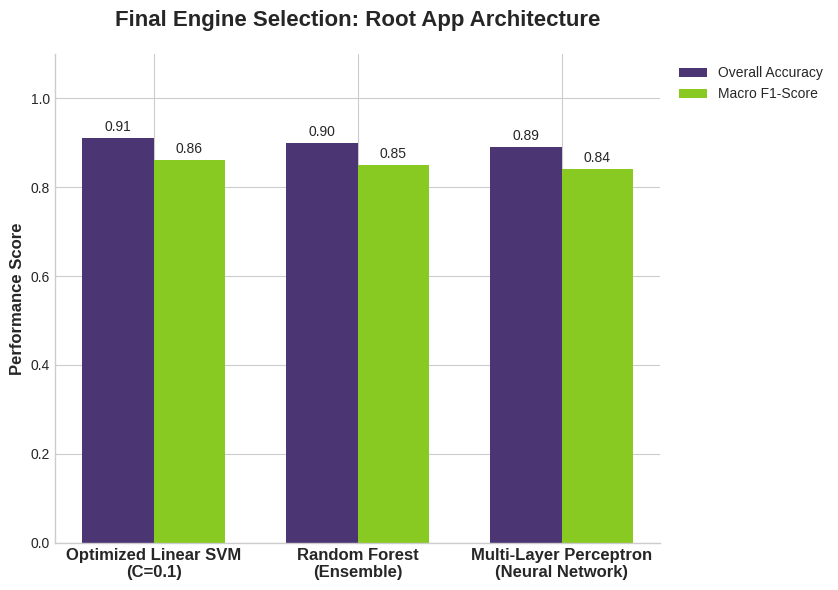

In [63]:
import numpy as np

# Define our three tested architectures
models = ['Optimized Linear SVM\n(C=0.1)', 'Random Forest\n(Ensemble)', 'Multi-Layer Perceptron\n(Neural Network)']

# Final performance metrics from our classification reports
accuracies = [0.91, 0.90, 0.89]
macro_f1s = [0.86, 0.85, 0.84]

x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

# Plotting the bars
rects1 = ax.bar(x - width/2, accuracies, width, label='Overall Accuracy', color='#4B3673')
rects2 = ax.bar(x + width/2, macro_f1s, width, label='Macro F1-Score', color='#88C922')

# Formatting the graph
ax.set_ylabel('Performance Score', fontsize=12, fontweight='bold')
ax.set_title('Final Engine Selection: Root App Architecture', fontsize=16, fontweight='bold', pad=20)
ax.set_xticks(x)
ax.set_xticklabels(models, fontsize=12, fontweight='bold')
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left')

# Adding the exact data labels on top of the bars
ax.bar_label(rects1, padding=3, fmt='%.2f')
ax.bar_label(rects2, padding=3, fmt='%.2f')

sns.despine()
plt.tight_layout(rect=[0, 0, 0.85, 1])
plt.ylim(0, 1.1)
plt.show()

<h2 style="font-family: 'Times New Roman', Times, serif;">
    Conclusion: The Future of the Root Engine
</h2>

<div style="font-family: 'Times New Roman', Times, serif; line-height: 1.6; font-size:20px;">
After the architectural evaluation, the Optimized Linear SVM emerges as the definitive classification engine for the Root application. Achieving a 91% accuracy and a 0.86 Macro F1-score, it consistently outperformed more complex ensemble and deep learning models. Our analysis proved that in the sparse, high dimensional vector space of TF-IDF features, a well-tuned linear hyperplane generalizes emotional boundaries more effectively than non-linear architectures, which tended to overfit on the noisy nuances of internet-sourced vocabulary. 
<br><br>
Beyond the math, this project revealed a critical insight for the future of Root, the lexical predictors for love means its necessary to transition to a domain specific dataset grounded in parental and pedagogical language. For the Root app to truly break generational trauma and foster regulation, the engine must eventually be fine-tuned on data that reflects the calm, regulated vocabulary of the Finnish and Montessori models.

Regardless, we have successfully engineered a lightweight, computationally efficient foundation. This SVM architecture provides the speed and precision required for feedback, allowing parents to transform moments of emotional flooding into moments of connection. By establishing this technical root, we have cleared the path for the next phase of development. Next we can focus on integrating these predictions into a holistic UI designed to help parents stay rooted, regulated, and ready to lead the next generation.
</div>